## jeu 1
Ici je présenterai le premier jeu de données, et répondrai aux questions joint en ordre. Les visualisation pertinentes seront présenté ainsi.

Commencons par charger les données.

In [442]:
import pandas as pd

df = pd.read_csv('plateforme_apprentissage.csv')
df

,id_apprenant,methode,niveau_initial,score_final,reussite,age,region,heures_etude
0,AP0001,B,intermédiaire,70.6,1,38,Québec,28.1
1,AP0002,B,débutant,52.5,0,32,Outaouais,21.9
2,AP0003,A,avancé,56.2,0,21,Hors Québec,23.5
3,AP0004,A,avancé,70.5,1,36,Outaouais,17.8
4,AP0005,B,débutant,81.7,1,33,Québec,29.3
...,...,...,...,...,...,...,...,...
2395,AP2396,B,débutant,49.3,0,39,Hors Québec,26.8
2396,AP2397,B,débutant,83.7,1,42,Montréal,22.9
2397,AP2398,A,intermédiaire,51.5,0,19,Hors Québec,22.8
2398,AP2399,B,débutant,51.1,0,26,Outaouais,18.3


### Passerelle vers le rapport LaTeX

Tout chiffre cité dans le rapport sort d'ici. On l'enregistre avec `val()`
ou `pct()`, puis `ecrire_valeurs()` les dépose dans `resultats/valeurs.tex`,
que le `.tex` relit à chaque compilation via `\val{clé}`. Les tableaux
passent par `ecrire_tableau()` et se chargent avec `\tbl{nom}`.

Aucun nombre n'est donc recopié à la main dans le rapport : il suffit de
réexécuter le notebook pour que le PDF suive.


In [443]:
from pathlib import Path

DOSSIER_RESULTATS = Path("resultats")
DOSSIER_RESULTATS.mkdir(exist_ok=True)

_valeurs = {}


def val(cle, valeur, dec=1, unite=""):
    """Enregistre un chiffre destiné au rapport et le renvoie inchangé."""
    if isinstance(valeur, str):
        texte = valeur
    elif dec == 0:
        texte = f"{round(valeur):d}"
    else:
        texte = f"{valeur:.{dec}f}".replace(".", ",")  # virgule décimale
    # Un « - » de clavier est un trait d'union : mauvais glyphe, et LaTeX
    # y autorise une coupure de ligne. On impose le vrai signe moins.
    if texte.startswith("-"):
        texte = "$-$" + texte[1:]
    _valeurs[cle.replace("_", "-")] = texte + unite
    return valeur


def pct(cle, proportion, dec=1):
    """Idem, pour une proportion entre 0 et 1 rendue en pourcentage."""
    return val(cle, 100 * proportion, dec=dec, unite=r"\,\%")


def ecrire_valeurs(nom="valeurs.tex"):
    """Écrit toutes les valeurs enregistrées dans resultats/valeurs.tex."""
    chemin = DOSSIER_RESULTATS / nom
    lignes = ["% Généré par le notebook -- ne pas éditer à la main.\n"]
    for cle, texte in sorted(_valeurs.items()):
        lignes.append(f"\\expandafter\\gdef\\csname val@{cle}\\endcsname{{{texte}}}\n")
    chemin.write_text("".join(lignes), encoding="utf-8")
    print(f"{len(_valeurs)} valeurs écrites dans {chemin}")


def ecrire_tableau(nom, tableau, **kwargs):
    """Dépose un tableau LaTeX (booktabs) que le rapport charge via \\tbl{nom}."""
    chemin = DOSSIER_RESULTATS / f"{nom.replace('_', '-')}.tex"
    kwargs.setdefault("float_format", "%.1f")
    chemin.write_text(tableau.to_latex(**kwargs), encoding="utf-8")
    print(f"tableau écrit dans {chemin}")


### Q1 Comparez le taux de réussite global des deux méthodes. Laquelle recommanderiez-vous à la direction de la plateforme?

Pour ceci nous allons séparer les deux méthodes, et trouver les taux de réussite pour chacune.
Je vais commencer par verifier que methode et reussite n'ont pas de nuls, ou valeurs abérantes/éronnées.
Ensuite je vais faire 2 DF, DF_A et DF_B.
En calculant la moyenne, nous aurons le taux de réussite.

In [444]:
df.methode.value_counts(dropna=False)

methode
B    1200
A    1200
Name: count, dtype: int64

In [445]:
df.reussite.value_counts(dropna=False)

reussite
1    1385
0    1015
Name: count, dtype: int64

In [446]:
df_a=df[df['methode'] == 'A']
df_b=df[df['methode'] == 'B']
taux_a= df_a.reussite.mean()
taux_b= df_b.reussite.mean()
print(f"le taux de réussite pour la méthode A est de {taux_a:.2%}")
print(f"le taux de réussite pour la méthode B est de {taux_b:.2%}")

le taux de réussite pour la méthode A est de 70.33%
le taux de réussite pour la méthode B est de 45.08%


In [447]:
# Les chiffres de Q1 partent vers le rapport.
pct("jeu1-taux-a", taux_a)
pct("jeu1-taux-b", taux_b)
val("jeu1-n-a", len(df_a), dec=0)
val("jeu1-n-b", len(df_b), dec=0)
val("jeu1-ecart", abs(100 * (taux_b - taux_a)), dec=1, unite=r"\,points")

ecrire_valeurs()


5 valeurs écrites dans resultats/valeurs.tex


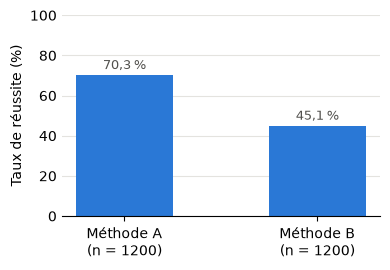

In [448]:
# [IA] Code généré par Claude : figure du taux de réussite par méthode (jeu 1, Q1)
# Figure Q1 : taux de réussite (en %) pour chaque méthode.
import matplotlib.pyplot as plt

DOSSIER_FIGURES = Path("figures")
DOSSIER_FIGURES.mkdir(exist_ok=True)

methodes = ["A", "B"]
groupes = [df_a, df_b]
part_reussite = [100 * g.reussite.mean() for g in groupes]

fig, ax = plt.subplots(figsize=(4, 2.8))
barres = ax.bar([f"Méthode {m}\n(n = {len(g)})" for m, g in zip(methodes, groupes)],
                part_reussite, width=0.5, color="#2a78d6")

# Pourcentage au-dessus de chaque barre, avec virgule décimale.
ax.bar_label(barres, labels=[f"{h:.1f} %".replace(".", ",") for h in barres.datavalues],
             padding=2, fontsize=9, color="#52514e")

ax.set_ylabel("Taux de réussite (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for cote in ("top", "right", "left"):
    ax.spines[cote].set_visible(False)
ax.tick_params(axis="y", length=0)

fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "jeu1_reussite.pdf")
plt.show()

### Q2 Reprenez la même comparaison à l’intérieur de chaque niveau initial. Présentez le résultat sous forme de tableau.

ici nous allons séparé les niveau, et le taux de réussite par niveau.
Ceci permettera d'avoir un meilleur apperçu de chaque méthode.
On veut voir le moyenne des résultats par niveau initial.
Par exemple, on pourrait s'attendre a ce que le niveau avancé ai un meilleur taux de réusite toujours.

In [449]:

results_by_level = df.groupby(["niveau_initial", "methode"])["reussite"].agg(["mean","count"]).unstack()

# results_by_level.columns= [f"{stat} {methode}" for stat, methode in results_by_level.columns]
# arrondir et %
# for meth in ["A", "B"]:
results_by_level['mean']=round(results_by_level["mean"]*100, 1)
    # results_by_level.drop(columns=[f"mean {meth}"], inplace=True)


results_by_level.rename_axis("Niveau initial", inplace=True)
results_by_level.rename(columns={"mean": "Moyenne", "count": "Compte"}, inplace=True)

ecrire_tableau("jeu1-Q1",results_by_level)

results_by_level

tableau écrit dans resultats/jeu1-Q1.tex


Moyenne       Compte     
methode              A     B      A    B
Niveau initial                          
avancé            80.6  93.3    930   90
débutant          16.7  36.0     90  930
intermédiaire     43.9  67.8    180  180

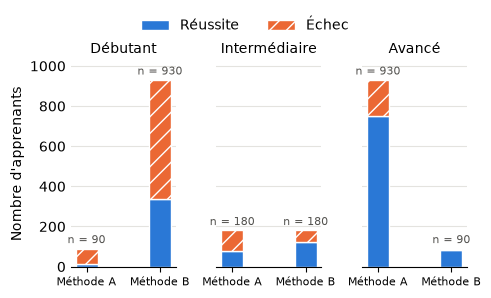

In [450]:
# [IA] Code généré par Claude : figure réussite / échec par méthode et par niveau (jeu 1, Q2)
# Un panneau par niveau initial ; dans chaque panneau, une barre par méthode,
# empilée en réussite (bas) et échec (haut). Hauteur totale = effectif.
niveaux = ["débutant", "intermédiaire", "avancé"]
comptes = pd.crosstab([df.niveau_initial, df.methode], df.reussite)

fig, axes = plt.subplots(1, len(niveaux), figsize=(5, 3), sharey=True)
for ax, niveau in zip(axes, niveaux):
    reussis = [comptes.loc[(niveau, m), 1] for m in methodes]
    echecs = [comptes.loc[(niveau, m), 0] for m in methodes]
    totaux = [r + e for r, e in zip(reussis, echecs)]

    ax.bar(methodes, reussis, width=0.3, color="#2a78d6", label="Réussite",
           edgecolor="white", linewidth=1)
    ax.bar(methodes, echecs, width=0.3, bottom=reussis, color="#eb6834", hatch="//",
           label="Échec", edgecolor="white", linewidth=1)

    # Effectif total au-dessus de chaque barre.
    for x, n in zip(methodes, totaux):
        ax.annotate(f"n = {n}", (x, n), xytext=(0, 2), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, color="#52514e")

    ax.set_title(niveau.capitalize(), fontsize=10)
    ax.set_xticks(range(len(methodes)), [f"Méthode {m}" for m in methodes], fontsize=8)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for cote in ("top", "right", "left"):
        ax.spines[cote].set_visible(False)
    ax.tick_params(axis="y", length=0)

axes[0].set_ylabel("Nombre d'apprenants")
axes[0].set_ylim(0, 1.1 * comptes.sum(axis=1).max())
poignees, etiquettes = axes[0].get_legend_handles_labels()
fig.legend(poignees, etiquettes, loc="upper center", ncols=2, frameon=False,
           bbox_to_anchor=(0.5, 1.0))

fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(DOSSIER_FIGURES / "jeu1_niveau.pdf")
plt.show()

### Q4  Recalculez un taux global pour chaque méthode, en pondérant cette fois les taux par niveau par les effectifs de l’ensemble du groupe, et non par ceux de chaque méthode. Quelle méthode recommandez-vous au terme de votre analyse?

En pondérant les taux globaux selon le nombre d'éffectifs, la différence de 840 entre les méthodes pour avancé et débutant sera corrigé.
Ceci donnera une moyenne global de chaque méthode non biaisé par les niveau de départ.


In [451]:
results_by_level['Compte total'] = results_by_level['Compte'].sum(axis=1)
results_by_level["Moyenne B Pondérée"]= results_by_level["Moyenne"]["B"]*results_by_level["Compte total"]/results_by_level["Compte total"].sum()
mean_b_adjusted=results_by_level["Moyenne B Pondérée"].sum()
results_by_level["Moyenne A Pondérée"]= results_by_level["Moyenne"]["A"]*results_by_level["Compte total"]/results_by_level["Compte total"].sum()
mean_a_adjusted=results_by_level["Moyenne A Pondérée"].sum()
print(f"le taux de réussite pondéré pour la méthode A est de {mean_a_adjusted}")
print(f"le taux de réussite pondéré pour la méthode B est de {mean_b_adjusted}")

le taux de réussite pondéré pour la méthode A est de 47.93750000000001
le taux de réussite pondéré pour la méthode B est de 65.1225


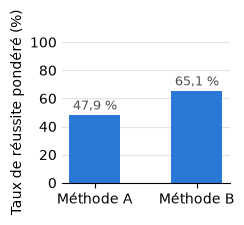

In [452]:
# [IA] Code généré par Claude : figure du taux de réussite pondéré par méthode (jeu 1, Q4)
# Même présentation que la figure Q1, avec les taux pondérés par les effectifs du groupe.
taux_ponderes = [mean_a_adjusted, mean_b_adjusted]

fig, ax = plt.subplots(figsize=(2.5, 2))
barres = ax.bar([f"Méthode {m}" for m in methodes], taux_ponderes, width=0.5, color="#2a78d6")

# Pourcentage au-dessus de chaque barre, avec virgule décimale.
ax.bar_label(barres, labels=[f"{h:.1f} %".replace(".", ",") for h in barres.datavalues],
             padding=2, fontsize=9, color="#52514e")

ax.set_ylabel("Taux de réussite pondéré (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for cote in ("top", "right", "left"):
    ax.spines[cote].set_visible(False)
ax.tick_params(axis="y", length=0)

fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "jeu1_reussite_ponderee.pdf")
plt.show()

### Q5 Reprenez la démarche de la question 2 avec l’une des colonnes age, region ou heures_etude. Comparez ce que vous obtenez avec le résultat de la question 2 et commentez.

Nous allons le répété avec région, car il n'a que 4 régions.

In [453]:
results_by_region = df.groupby(["region", "methode"])["reussite"].agg(["mean","count"]).unstack()

# results_by_level.columns= [f"{stat} {methode}" for stat, methode in results_by_level.columns]
# arrondir et %
# for meth in ["A", "B"]:
results_by_region['mean']=round(results_by_region["mean"]*100, 1)
    # results_by_level.drop(columns=[f"mean {meth}"], inplace=True)


results_by_region.rename_axis("region", inplace=True)
results_by_region.rename(columns={"mean": "Moyenne", "count": "Compte"}, inplace=True)



results_by_region

Moyenne       Compte     
methode           A     B      A    B
region                               
Hors Québec    69.5  44.0    341  309
Montréal       68.2  46.5    302  303
Outaouais      69.5  44.9    282  263
Québec         74.5  44.9    275  325

In [454]:
# [IA] Code généré par Claude : export du tableau par région vers le rapport (jeu 1, Q5)
ecrire_tableau("jeu1-Q5", results_by_region)

tableau écrit dans resultats/jeu1-Q5.tex


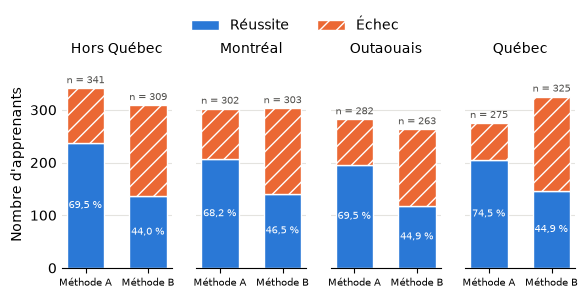

In [455]:
# [IA] Code généré par Claude : figure réussite / échec par méthode et par région (jeu 1, Q5)
# Même présentation que la figure Q2 : un panneau par région ; dans chaque panneau,
# une barre par méthode, empilée en réussite (bas) et échec (haut). Hauteur totale = effectif.
regions = sorted(df.region.unique())
comptes_region = pd.crosstab([df.region, df.methode], df.reussite)

fig, axes = plt.subplots(1, len(regions), figsize=(6, 3), sharey=True)
for ax, region in zip(axes, regions):
    reussis = [comptes_region.loc[(region, m), 1] for m in methodes]
    echecs = [comptes_region.loc[(region, m), 0] for m in methodes]
    totaux = [r + e for r, e in zip(reussis, echecs)]

    barres_reussite = ax.bar(methodes, reussis, width=0.6, color="#2a78d6", label="Réussite",
                             edgecolor="white", linewidth=1)
    ax.bar(methodes, echecs, width=0.6, bottom=reussis, color="#eb6834", hatch="//",
           label="Échec", edgecolor="white", linewidth=1)

    # Taux de réussite (%) au centre de la partie réussite, avec virgule décimale.
    ax.bar_label(barres_reussite,
                 labels=[f"{100 * r / t:.1f} %".replace(".", ",") for r, t in zip(reussis, totaux)],
                 label_type="center", fontsize=7, color="white")

    # Effectif total au-dessus de chaque barre.
    for x, n in zip(methodes, totaux):
        ax.annotate(f"n = {n}", (x, n), xytext=(0, 2), textcoords="offset points",
                    ha="center", va="bottom", fontsize=7, color="#52514e")

    ax.set_title(region, fontsize=10)
    ax.set_xticks(range(len(methodes)), [f"Méthode {m}" for m in methodes], fontsize=7)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for cote in ("top", "right", "left"):
        ax.spines[cote].set_visible(False)
    ax.tick_params(axis="y", length=0)

axes[0].set_ylabel("Nombre d'apprenants")
axes[0].set_ylim(0, 1.15 * comptes_region.sum(axis=1).max())
poignees, etiquettes = axes[0].get_legend_handles_labels()
fig.legend(poignees, etiquettes, loc="upper center", ncols=2, frameon=False,
           bbox_to_anchor=(0.5, 1.0))

fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(DOSSIER_FIGURES / "jeu1_region.pdf")
plt.show()

## Jeu 2 -  consommation électrique d’un immeuble de bureaux

Suite pour jeu deux cette fois.

Chargons les données.

In [456]:
df_j2=pd.read_csv('consommation_batiment.csv')
df_j2

,date,jour_semaine,jour_ferie,temperature_c,occupation_pct,consommation_kwh
0,2023-01-01,dimanche,1,8.5,16.7,572.1
1,2023-01-02,lundi,0,1.6,67.1,1172.2
2,2023-01-03,mardi,0,6.7,72.2,954.8
3,2023-01-04,mercredi,0,4.2,69.0,943.4
4,2023-01-05,jeudi,0,3.7,74.1,1065.7
...,...,...,...,...,...,...
1090,2025-12-26,vendredi,1,7.4,12.0,764.9
1091,2025-12-27,samedi,0,2.7,18.9,826.1
1092,2025-12-28,dimanche,0,8.0,7.3,578.0
1093,2025-12-29,lundi,0,3.6,88.3,1079.1


In [457]:
df_j2.describe()

,jour_ferie,temperature_c,occupation_pct,consommation_kwh
count,1095.000000,1095.000000,1095.000000,1095.000000
mean,0.013699,15.450502,52.966849,854.081735
std,0.116290,9.123651,28.042341,244.460953
min,0.000000,-4.400000,2.000000,250.400000
25%,0.000000,7.200000,15.900000,679.700000
50%,0.000000,15.700000,65.800000,860.300000
75%,0.000000,23.700000,73.550000,1033.800000
max,1.000000,35.600000,97.800000,1679.100000


In [458]:
df_j2.isna().sum()

date                0
jour_semaine        0
jour_ferie          0
temperature_c       0
occupation_pct      0
consommation_kwh    0
dtype: int64

### Q1 Calculez le coefficient de corrélation entre la température extérieure et la consommation. Interprétez cette valeur en une phrase.

Aucun nuls, aucun max ou min qui semble aberant rapidement.

validons le coefficient de corrélation

In [459]:
correlation_coef= float(df_j2["consommation_kwh"].corr(df_j2["temperature_c"]))

val('correlation_coef', correlation_coef, dec=4)
ecrire_valeurs()
correlation_coef

6 valeurs écrites dans resultats/valeurs.tex


0.011862263776120653

### Q2 Tracez le nuage de points de la consommation en fonction de la température. Décrivez la forme obtenue et commentez-la au regard de la valeur calculée à la question 1.

Tracons un nuage de points de la corrélation entre les deux variable.
Avec le résultat de l'étape 1, on peut s'attendre a ce que les deux variable n'ont aucune corrélation.


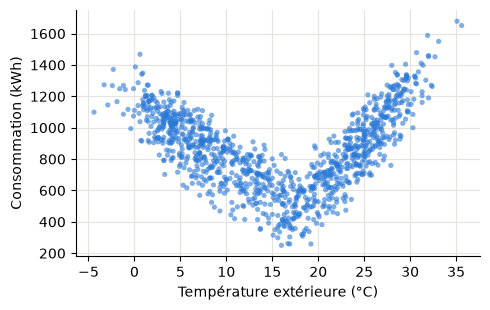

In [460]:
# [IA] Code généré par Claude : nuage de points consommation / température (jeu 2, Q2)
# Un point par jour : température extérieure en abscisse, consommation en ordonnée.
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.scatter(df_j2["temperature_c"], df_j2["consommation_kwh"],
           s=14, color="#2a78d6", alpha=0.6, edgecolors="none")

ax.set_xlabel("Température extérieure (°C)")
ax.set_ylabel("Consommation (kWh)")
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for cote in ("top", "right"):
    ax.spines[cote].set_visible(False)

fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "jeu2_nuage_conso_temperature.pdf")
plt.show()


### Q3 Séparez les journées en deux groupes selon un seuil de température que vous choisirez et justifierez. Calculez le coefficient de corrélation dans chacun des deux groupes et comparez avec la question 1.

Au lieu de choisir une valeur, je vais testé les valeurs entre 15 et 20, et voir ou les coefficients se stabilise. 
On veut avoir un coefficient des deux sections qui sont maximales.
Selon les données, il y a surement plus d'une valeur qui donnera des coeficients similaires

In [461]:
upper_limit=20
limit=15
coefs= []
while limit<=upper_limit:
    masque= df_j2["temperature_c"]<limit
    froid = df_j2[masque]
    chaud = df_j2[~masque]
    coef_froid= float(froid["consommation_kwh"].corr(froid["temperature_c"]))
    coef_chaud= float(chaud["consommation_kwh"].corr(chaud["temperature_c"]))
    coefs.append({"limite": limit, "coef_froid": coef_froid, "coef_chaud": coef_chaud, "coef_total": ((-coef_froid) + coef_chaud)})
    limit+=.1
    limit= round(limit, 1)

df_coefs = pd.DataFrame(coefs)
df_coefs



,limite,coef_froid,coef_chaud,coef_total
0,15.0,-0.780555,0.877958,1.658513
1,15.1,-0.782771,0.882374,1.665145
2,15.2,-0.785420,0.881856,1.667276
3,15.3,-0.785615,0.884170,1.669786
4,15.4,-0.788399,0.883583,1.671982
5,15.5,-0.788399,0.883583,1.671982
6,15.6,-0.788649,0.885594,1.674243
7,15.7,-0.794256,0.883965,1.678221
8,15.8,-0.797138,0.884117,1.681255
9,15.9,-0.799466,0.883598,1.683064


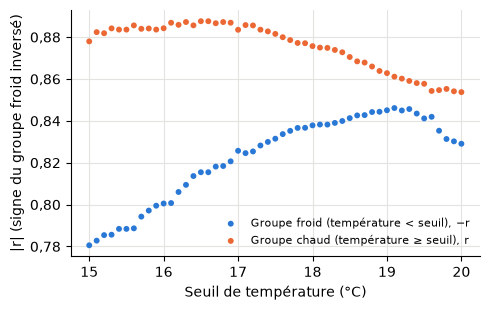

In [462]:
# [IA] Code généré par Claude : coefficients de corrélation selon le seuil de température (jeu 2, Q3)
# Un seul graphique : r du groupe chaud et −r du groupe froid (signe inversé pour que
# les deux séries partagent la même échelle), pour chaque seuil testé.
fig, ax = plt.subplots(figsize=(5, 3.2))
series = [(-df_coefs["coef_froid"], "#2a78d6", "Groupe froid (température < seuil), −r"),
          (df_coefs["coef_chaud"], "#eb6834", "Groupe chaud (température ≥ seuil), r")]

for valeurs, couleur, etiquette in series:
    ax.scatter(df_coefs["limite"], valeurs, s=18, color=couleur,
               edgecolors="none", label=etiquette)

ax.set_xlabel("Seuil de température (°C)")
ax.set_ylabel("|r| (signe du groupe froid inversé)")
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for cote in ("top", "right"):
    ax.spines[cote].set_visible(False)
ax.legend(fontsize=8, frameon=False, loc="best")

# Virgule décimale sur les axes
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.2f}".replace(".", ",").replace("-", "−"))
ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}".replace(".", ","))

fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "jeu2_coefs_par_seuil.pdf")
plt.show()


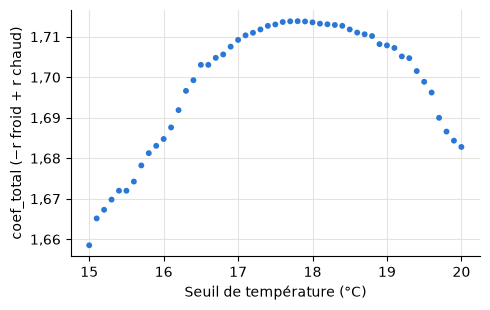

In [463]:
# [IA] Code généré par Claude : coef_total selon le seuil de température (jeu 2, Q3)
# Un point par seuil testé : valeur de la colonne coef_total de df_coefs.
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.scatter(df_coefs["limite"], df_coefs["coef_total"], s=18, color="#2a78d6", edgecolors="none")

ax.set_xlabel("Seuil de température (°C)")
ax.set_ylabel("coef_total (−r froid + r chaud)")
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for cote in ("top", "right"):
    ax.spines[cote].set_visible(False)

# Virgule décimale sur les axes
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.2f}".replace(".", ",").replace("-", "−"))
ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}".replace(".", ","))

fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "jeu2_coef_total_par_seuil.pdf")
plt.show()


In [464]:
max_coefs=float(df_coefs["coef_total"].max())
df_coefs[df_coefs["coef_total"] == max_coefs]
coef_chaud=float(df_coefs[df_coefs["coef_total"] == max_coefs]["coef_chaud"].values[0])
coef_froid=float(df_coefs[df_coefs["coef_total"] == max_coefs]["coef_froid"].values[0])
seuil_optimal=float(df_coefs[df_coefs["coef_total"] == max_coefs]["limite"].values[0])

val('coef_froid', coef_froid, dec=4)
val('coef_chaud', coef_chaud, dec=4)
val('seuil-optimal', seuil_optimal, dec=2)
ecrire_valeurs()
df_coefs[df_coefs["coef_total"] == max_coefs]

9 valeurs écrites dans resultats/valeurs.tex


,limite,coef_froid,coef_chaud,coef_total
28,17.8,-0.836613,0.877205,1.713818


### Q4 Autour de quelle température la consommation est-elle minimale? Proposez une explication physique de la forme observée.

trouvons la consommation moyenne pour chaque temperature observé, et la valeur minimale de ceci sera notre valeur.

In [465]:
consomation_par_temp = df_j2.groupby(["temperature_c"])["consommation_kwh"].mean()

temp_min = float(consomation_par_temp.idxmin())   
print(f"la température pour laquelle la consommation est minimale est de {temp_min} °C")

val("jeu2-temp-min", temp_min, dec=1)
ecrire_valeurs()

la température pour laquelle la consommation est minimale est de 16.9 °C
10 valeurs écrites dans resultats/valeurs.tex


### q5 Les colonnes occupation_pct et jour_ferie décrivent le calendrier d’utilisation du bâtiment. Évaluez la part de la consommation qu’elles expliquent, puis vérifiez si elles sont ou non liées à la température. Expliquez pourquoi cette seconde vérification est nécessaire.

Je vais regarder si certain jours fériés tombe une journée de fin de semaine. 
Si c'est le cas je devrais faire plus de transformation pour exclure ceci.

In [466]:
masque= df_j2["jour_semaine"].isin(["samedi", "dimanche"]) & (df_j2["jour_ferie"] == 1)
weekend_feries = df_j2[masque]
weekend_feries

,date,jour_semaine,jour_ferie,temperature_c,occupation_pct,consommation_kwh
0,2023-01-01,dimanche,1,8.5,16.7,572.1
174,2023-06-24,samedi,1,29.7,14.5,1108.4
181,2023-07-01,samedi,1,26.9,12.3,899.7


Certains jours fériés sont une fin de semaine. Regardons si l'occupation d'une journée férié et fin de semaine sont similaires

In [467]:
# [IA] Code généré par Claude : rappel de syntaxe pandas, moyenne de occupation_pct par sous-groupe
weekend = df_j2["jour_semaine"].isin(["samedi", "dimanche"])
ferie = df_j2["jour_ferie"] == 1

# [IA] Code généré par Claude : rappel de syntaxe pandas, tableau moyenne / variance par sous-groupe
stats = ["mean", "std", "count"]
groupes = {
    "Férié": ferie,
    "Fin de semaine": weekend,
    'fin de semaine non fériée': weekend & ~ferie,
    'fin de semaine fériée': weekend & ferie,
    "Semaine": ~weekend,
    "Semaine non fériée": ~weekend & ~ferie,
    'semaine fériée': ~weekend & ferie
}
tableau_occ = pd.DataFrame({
    nom: df_j2.loc[masque, "occupation_pct"].agg(stats) for nom, masque in groupes.items()
}).T
tableau_occ

,mean,std,count
Férié,11.933333,2.296167,15.0
Fin de semaine,11.522364,4.276682,313.0
fin de semaine non fériée,11.493548,4.283613,310.0
fin de semaine fériée,14.500000,2.200000,3.0
Semaine,69.555243,11.415547,782.0
Semaine non fériée,70.463247,8.859970,770.0
semaine fériée,11.291667,1.893270,12.0


Avec ce tableau, on peut voir que les journées fériés se comporte comme les journées de fin de semaine, et les journées de semaine non fériés se comporte différement.
Les deux semble avoir de l'occupation bien différente

Validons si ceux ci son corrélés avec l'occupation.
Il risque de l'être considerant l'information obenus plus haut. 
Nous allons ensuite pouvoir valider qu'il ont environ la même corrélation avec la consommation.

Ensuite si temperature et ces deux variables ont une correlation quasi-nul, on pourra affirmé qu'ils n'affectent pas la corélation dans la même direction.


In [468]:
# [IA] Code généré par Claude : rappel de syntaxe pandas, corrélation avec une variable binaire
indicateur = (~weekend & ~ferie).astype(int)     # 1 = semaine non fériée, 0 = autre
corre_occ= float(df_j2["occupation_pct"].corr(indicateur))

val("jeu2-corr-occ", corre_occ, dec=2)
ecrire_valeurs()

corre_occ

11 valeurs écrites dans resultats/valeurs.tex


0.9608076300453994

In [469]:
# [IA] Code généré par Claude : rappel de syntaxe pandas, corrélation avec une variable binaire
indicateur = (~weekend & ~ferie).astype(int)     # 1 = semaine non fériée, 0 = autre
corre_occ_ferie= float(df_j2["consommation_kwh"].corr(indicateur))

val("jeu2-corr-occ-ferie", corre_occ_ferie, dec=2)
ecrire_valeurs()

corre_occ_ferie

12 valeurs écrites dans resultats/valeurs.tex


0.3408975950252961

In [470]:
# [IA] Code généré par Claude : rappel de syntaxe pandas, corrélation avec une variable binaire
indicateur = (~weekend & ~ferie).astype(int)     # 1 = semaine non fériée, 0 = autre
corre_occ_cons= float(df_j2["consommation_kwh"].corr(df_j2["occupation_pct"]))

val("jeu2-corr-occ-cons", corre_occ_cons, dec=2)
ecrire_valeurs()

corre_occ_cons

13 valeurs écrites dans resultats/valeurs.tex


0.35761456382990314

In [471]:
# [IA] Code généré par Claude : rappel de syntaxe pandas, corrélation avec une variable binaire
indicateur = (~weekend & ~ferie).astype(int)     # 1 = semaine non fériée, 0 = autre
corre_jour_temp= float(df_j2["temperature_c"].corr(indicateur))

val("jeu2-jour-temp", corre_jour_temp, dec=2)
ecrire_valeurs()

corre_jour_temp

14 valeurs écrites dans resultats/valeurs.tex


0.005022607554354674

In [472]:

corre_occ_temp= float(df_j2["temperature_c"].corr(df_j2["occupation_pct"]))

val("jeu2-occ-temp", corre_occ_temp, dec=2)
ecrire_valeurs()

corre_occ_temp

15 valeurs écrites dans resultats/valeurs.tex


-0.004175469463010264

In [473]:
# [IA] Code généré par Claude : tableau des corrélations de Q5 pour le rapport (jeu 2, Q5)
# Regroupe les coefficients calculés dans les cellules précédentes, une ligne par paire.
indicateur_nom = "Semaine non fériée (0/1)"
tableau_corr = pd.DataFrame(
    [
        (r"Occupation (\%)", indicateur_nom, corre_occ),
        ("Consommation (kWh)", indicateur_nom, corre_occ_ferie),
        ("Consommation (kWh)", r"Occupation (\%)", corre_occ_cons),
        ("Température (°C)", indicateur_nom, corre_jour_temp),
        ("Température (°C)", r"Occupation (\%)", corre_occ_temp),
    ],
    columns=["Variable 1", "Variable 2", "r"],
)

# Deux décimales, virgule décimale et vrai signe moins, comme val().
# (Le « % » est échappé dans les libellés : en LaTeX, il ouvre un commentaire.)
def format_r(x):
    texte = f"{x:.2f}".replace(".", ",")
    if texte in ("-0,00", "0,00"):
        return "0,00"  # pas de « −0,00 » quand l'arrondi donne zéro
    return "$-$" + texte[1:] if texte.startswith("-") else texte

ecrire_tableau("jeu2-Q5-correlations", tableau_corr, index=False, float_format=format_r)
tableau_corr


tableau écrit dans resultats/jeu2-Q5-correlations.tex


,Variable 1,Variable 2,r
0,Occupation (\%),Semaine non fériée (0/1),0.960808
1,Consommation (kWh),Semaine non fériée (0/1),0.340898
2,Consommation (kWh),Occupation (\%),0.357615
3,Température (°C),Semaine non fériée (0/1),0.005023
4,Température (°C),Occupation (\%),-0.004175


##  Jeu 3 : dossiers de patients d’une clinique

Commencons en important les données

In [474]:
df_j3=pd.read_csv('dossiers_patients.csv')
df_j3


,id_patient,sexe,age,tension_systolique,taille_cm,poids_kg,tabagisme
0,PT0001,M,61,140,155.3,50.9,ancien
1,PT0002,F,60,136,167.9,74.1,actuel
2,PT0003,F,80,144,179.6,79.4,non
3,PT0004,F,56,121,162.0,72.4,non
4,PT0005,F,59,138,182.1,87.9,ancien
...,...,...,...,...,...,...,...
795,PT0796,F,46,115,196.7,75.2,non
796,PT0797,F,55,123,177.2,79.0,ancien
797,PT0798,M,35,133,176.9,96.2,actuel
798,PT0799,F,85,120,155.8,55.0,non


### Q1 Produisez une description statistique de chaque colonne numérique, en examinant notamment son minimum et son maximum. Relevez les anomalies éventuelles. Pour chacune : sa nature, le nombre de lignes concernées, et la manière dont vous l’avez détectée.

In [475]:
df_j3.describe()

,age,tension_systolique,taille_cm,poids_kg
count,800.000000,800.000000,800.000000,800.000000
mean,98.633750,122.343750,164.272812,77.243250
std,207.246963,25.481164,33.304289,14.554459
min,18.000000,-1.000000,1.540000,37.000000
25%,41.000000,117.000000,163.200000,67.000000
50%,52.000000,126.000000,170.100000,76.250000
75%,64.000000,135.000000,176.425000,87.300000
max,999.000000,164.000000,196.700000,121.100000


In [476]:
# [IA] Code généré par Claude : moyenne et médiane de l'âge (données brutes) envoyées au rapport
age_moyenne_brut = float(df_j3["age"].mean())
age_mediane_brut = float(df_j3["age"].median())

val("jeu3-age-moyenne-brut", age_moyenne_brut, dec=1)
val("jeu3-age-mediane-brut", age_mediane_brut, dec=1)
ecrire_valeurs()

print(f"Âge moyen (brut) : {age_moyenne_brut:.1f}")
print(f"Âge médian (brut) : {age_mediane_brut:.1f}")

17 valeurs écrites dans resultats/valeurs.tex
Âge moyen (brut) : 98.6
Âge médian (brut) : 52.0


In [477]:
# [IA] Code généré par Claude : export du tableau describe() de df_j3 vers le rapport (jeu 3, Q1)
# Libellés en français ; virgule décimale et vrai signe moins, comme val().
def format_nombre(x, dec=1):
    texte = f"{x:.{dec}f}".replace(".", ",")
    return "$-$" + texte[1:] if texte.startswith("-") else texte

description_j3 = df_j3.describe().rename(
    index={"count": "Effectif", "mean": "Moyenne", "std": "Écart-type", "min": "Minimum",
           "25%": "Q1", "50%": "Médiane", "75%": "Q3", "max": "Maximum"},
    columns={"age": "Âge", "tension_systolique": "Tension systolique",
             "taille_cm": "Taille (cm)", "poids_kg": "Poids (kg)"},
)
description_j3_tex = description_j3.map(format_nombre)
description_j3_tex.loc["Effectif"] = description_j3.loc["Effectif"].map(lambda x: format_nombre(x, 0))

ecrire_tableau("jeu3-Q1-description", description_j3_tex, column_format="lrrrr")
description_j3

tableau écrit dans resultats/jeu3-Q1-description.tex


,Âge,Tension systolique,Taille (cm),Poids (kg)
Effectif,800.000000,800.000000,800.000000,800.000000
Moyenne,98.633750,122.343750,164.272812,77.243250
Écart-type,207.246963,25.481164,33.304289,14.554459
Minimum,18.000000,-1.000000,1.540000,37.000000
Q1,41.000000,117.000000,163.200000,67.000000
Médiane,52.000000,126.000000,170.100000,76.250000
Q3,64.000000,135.000000,176.425000,87.300000
Maximum,999.000000,164.000000,196.700000,121.100000


In [478]:
# [IA] Code généré par Claude : modalités et effectifs de sexe et tabagisme
for col in ["sexe", "tabagisme"]:
    print(df_j3[col].value_counts(dropna=False), "\n")

sexe
F    427
M    373
Name: count, dtype: int64 

tabagisme
non       500
ancien    186
actuel    114
Name: count, dtype: int64 



Rapidement on peut voir quelques anomalies.

Tabagisme et sexe on uniquement des valeurs coérhentes.
une std pour l'age de 207 est impossible.
l'age max de 999 en est la cause.

Le min de tension systolique est impossible car une tension de systolique de -1 est impossible.

Meme chose pour le min de tail, car une taille de 1 cm est impossible.

Pour trouver les outlier regardons avec les quartilles.

In [479]:
# [IA] Code généré par Claude : fonction de détection des valeurs aberrantes (règle 1,5 × IQR)
def valeurs_aberrantes_iqr(df, col):
    serie = df[col]
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    borne_inf = q1 - 1.5 * iqr
    borne_sup = q3 + 1.5 * iqr

    masque = (serie < borne_inf) | (serie > borne_sup)

    print(f"--- {col} ---")
    print(f"Valeurs manquantes : {serie.isna().sum()}")
    print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}")
    print(f"Bornes : [{borne_inf}, {borne_sup}]")
    print(f"Nombre de valeurs aberrantes potentielles : {masque.sum()}")
    display(df.loc[masque].sort_values(col))
    return masque

In [480]:
# [IA] Code généré par Claude : application de la règle 1,5 × IQR aux quatre colonnes numériques
masque_age = valeurs_aberrantes_iqr(df_j3, "age")
masque_tension = valeurs_aberrantes_iqr(df_j3, "tension_systolique")
masque_taille = valeurs_aberrantes_iqr(df_j3, "taille_cm")
masque_poids = valeurs_aberrantes_iqr(df_j3, "poids_kg")

--- age ---
Valeurs manquantes : 0
Q1 = 41.0, Q3 = 64.0, IQR = 23.0
Bornes : [6.5, 98.5]
Nombre de valeurs aberrantes potentielles : 40


,id_patient,sexe,age,tension_systolique,taille_cm,poids_kg,tabagisme
35,PT0036,M,999,128,175.6,96.0,non
62,PT0063,M,999,122,162.3,66.7,non
71,PT0072,F,999,143,170.7,59.1,actuel
76,PT0077,M,999,132,184.2,64.1,ancien
85,PT0086,F,999,135,179.8,87.5,actuel
93,PT0094,M,999,129,156.9,63.7,non
95,PT0096,M,999,146,173.8,72.1,non
106,PT0107,F,999,112,177.4,99.5,non
155,PT0156,M,999,128,174.5,86.2,non
165,PT0166,F,999,135,179.9,113.0,non


--- tension_systolique ---
Valeurs manquantes : 0
Q1 = 117.0, Q3 = 135.0, IQR = 18.0
Bornes : [90.0, 162.0]
Nombre de valeurs aberrantes potentielles : 29


,id_patient,sexe,age,tension_systolique,taille_cm,poids_kg,tabagisme
14,PT0015,M,49,-1,186.2,95.0,non
37,PT0038,F,54,-1,175.3,83.4,non
60,PT0061,F,25,-1,188.0,77.2,ancien
119,PT0120,M,49,-1,169.0,71.1,ancien
124,PT0125,M,76,-1,185.3,94.7,actuel
237,PT0238,F,62,-1,166.7,64.6,ancien
231,PT0232,M,36,-1,170.1,66.6,ancien
228,PT0229,M,59,-1,175.1,80.6,non
317,PT0318,F,26,-1,169.4,70.7,non
325,PT0326,M,52,-1,160.5,72.2,ancien


--- taille_cm ---
Valeurs manquantes : 0
Q1 = 163.2, Q3 = 176.425, IQR = 13.225000000000023
Bornes : [143.36249999999995, 196.26250000000005]
Nombre de valeurs aberrantes potentielles : 32


,id_patient,sexe,age,tension_systolique,taille_cm,poids_kg,tabagisme
281,PT0282,M,43,121,1.54,72.6,non
794,PT0795,F,77,139,1.56,64.3,ancien
614,PT0615,M,45,144,1.56,85.3,non
550,PT0551,M,47,133,1.56,77.7,non
640,PT0641,F,59,133,1.60,82.2,non
643,PT0644,F,36,98,1.60,64.7,non
608,PT0609,F,18,122,1.63,87.6,non
511,PT0512,F,50,132,1.63,72.4,non
332,PT0333,M,41,117,1.65,89.7,non
276,PT0277,F,47,119,1.65,67.3,non


--- poids_kg ---
Valeurs manquantes : 0
Q1 = 67.0, Q3 = 87.3, IQR = 20.299999999999997
Bornes : [36.550000000000004, 117.75]
Nombre de valeurs aberrantes potentielles : 5


,id_patient,sexe,age,tension_systolique,taille_cm,poids_kg,tabagisme
611,PT0612,M,34,116,1.92,118.3,non
92,PT0093,F,76,163,187.10,118.8,actuel
496,PT0497,M,42,130,191.30,120.1,non
375,PT0376,M,62,143,177.50,120.4,non
432,PT0433,F,73,137,185.20,121.1,non


#### poids
Les poids abérants sont très proche de la borne suppérieur. Les valeurs sont possible, et probablement des gens de surpoids.
Il seront donc conservé tel quel.

#### taille_cm
Les tailles près de la borne suppérieurs, semble etre de grandes valeurs, pas des valeurs abérantes.
Ils seront conservés.
Les valeurs près de la borne inférieur, sont tant qu'à elle trop basse.
Après inspection ils sont entre 1.54 et 1.92.
Nous pouvons donc supposé qu'ils sont en m au lieu de cm. ils seront converties.


In [481]:
# [IA] Code généré par Claude : conversion en cm des tailles saisies en mètres, dans une copie de df_j3
# Lignes signalées par la règle IQR dont la valeur est sous 10 (donc en m, pas en cm).
# df_j3 reste intact ; les corrections se font dans df_j3_corrige.
df_j3_corrige = df_j3.copy()

masque_metres = masque_taille & (df_j3["taille_cm"] < 10)
print(f"Tailles converties de m en cm : {masque_metres.sum()}")
print(f"Plage avant conversion : [{df_j3.loc[masque_metres, 'taille_cm'].min()}, "
      f"{df_j3.loc[masque_metres, 'taille_cm'].max()}]")

df_j3_corrige.loc[masque_metres, "taille_cm"] = df_j3.loc[masque_metres, "taille_cm"] * 100

df_j3_corrige["taille_cm"].describe()

Tailles converties de m en cm : 30
Plage avant conversion : [1.54, 1.92]


count    800.000000
mean     170.615000
std        9.070261
min      148.000000
25%      164.100000
50%      170.650000
75%      176.600000
max      196.700000
Name: taille_cm, dtype: float64

#### tension
les tensions près de la borne suppérieur ne seront pas retirés, puisqu'il semble etre réel.
Les tensions de -1 doivent être invesigués.

In [482]:
# [IA] Code généré par Claude : plus proche voisin de chaque tension à -1 (même sexe et tabagisme, variables standardisées)
# Distance euclidienne sur age, taille_cm et poids_kg standardisés (z-scores).
# Voisins possibles : même sexe, même tabagisme, tension valide, âge différent de 999.
import numpy as np

colonnes_distance = ["age", "taille_cm", "poids_kg"]
age_valide = df_j3_corrige["age"] != 999

cibles = df_j3_corrige[df_j3_corrige["tension_systolique"] == -1]
candidats = df_j3_corrige[(df_j3_corrige["tension_systolique"] != -1) & age_valide]

# Moyennes et écarts-types calculés sans les âges à 999, pour qu'ils ne faussent pas l'échelle.
reference = df_j3_corrige.loc[age_valide, colonnes_distance]
moyennes, ecarts = reference.mean(), reference.std()
z_cibles = (cibles[colonnes_distance] - moyennes) / ecarts
z_candidats = (candidats[colonnes_distance] - moyennes) / ecarts

lignes = []
for idx, cible in cibles.iterrows():
    meme_groupe = (candidats["sexe"] == cible["sexe"]) & (candidats["tabagisme"] == cible["tabagisme"])
    distances = np.sqrt(((z_candidats[meme_groupe] - z_cibles.loc[idx]) ** 2).sum(axis=1))
    voisin = candidats.loc[distances.idxmin()]
    # Chaque valeur du patient est suivie de celle de son voisin.
    lignes.append({
        "id_patient": cible["id_patient"],
        "id_voisin": voisin["id_patient"],
        "sexe": cible["sexe"],
        "tabagisme": cible["tabagisme"],
        "age": cible["age"],
        "age_voisin": voisin["age"],
        "taille_cm": cible["taille_cm"],
        "taille_voisin": voisin["taille_cm"],
        "poids_kg": cible["poids_kg"],
        "poids_voisin": voisin["poids_kg"],
        "tension_voisin": voisin["tension_systolique"],
        "distance": round(distances.min(), 3),
    })

comparaison_tension = pd.DataFrame(lignes)
comparaison_tension

,id_patient,id_voisin,sexe,tabagisme,age,age_voisin,taille_cm,taille_voisin,poids_kg,poids_voisin,tension_voisin,distance
0,PT0015,PT0105,M,non,49,49,186.2,187.9,95.0,99.9,124,0.385
1,PT0038,PT0417,F,non,54,53,175.3,175.3,83.4,80.5,115,0.209
2,PT0061,PT0218,F,ancien,25,32,188.0,183.4,77.2,80.2,113,0.705
3,PT0120,PT0160,M,ancien,49,56,169.0,170.1,71.1,69.1,119,0.484
4,PT0125,PT0128,M,actuel,76,78,185.3,179.9,94.7,100.6,157,0.728
5,PT0229,PT0106,M,non,59,60,175.1,174.6,80.6,84.0,132,0.248
6,PT0232,PT0211,M,ancien,36,43,170.1,173.1,66.6,71.2,112,0.639
7,PT0238,PT0252,F,ancien,62,59,166.7,167.4,64.6,67.0,120,0.264
8,PT0259,PT0551,M,non,50,47,156.6,156.0,80.8,77.7,133,0.294
9,PT0318,PT0772,F,non,26,31,169.4,169.9,70.7,74.9,118,0.434


In [483]:
# [IA] Code généré par Claude : traduction d'une distance standardisée de 0,5 en écarts d'âge, de taille et de poids
# Distance = racine de la somme des carrés des écarts en z-scores (écarts-types de la cellule précédente).
# Cas extrême : toute la distance porte sur une seule variable -> écart max = 0,5 × écart-type.
# Cas réparti : la distance se partage également entre les 3 variables -> écart = 0,5 / √3 × écart-type.
seuil_distance = 0.3
traduction_seuil = pd.DataFrame({
    "écart-type": ecarts,
    "écart max (une seule variable)": seuil_distance * ecarts,
    "écart si réparti sur les 3": seuil_distance / np.sqrt(len(colonnes_distance)) * ecarts,
}).round(2)
traduction_seuil

,écart-type,écart max (une seule variable),écart si réparti sur les 3
age,15.61,4.68,2.70
taille_cm,9.14,2.74,1.58
poids_kg,14.56,4.37,2.52


In [484]:
# [IA] Code généré par Claude : imputation des tensions à -1 par moyenne pondérée (1/distance) des voisins à distance ≤ 0,3, suppression des patients sans voisin
# Voisins : tous les candidats du même sexe et tabagisme à distance ≤ seuil (variables de la cellule du plus proche voisin).
# Poids = 1 / distance ; si un voisin est à distance 0, seuls les voisins à distance 0 comptent (moyenne simple).
seuil_distance = 0.3

lignes_imputation = []
for idx, cible in cibles.iterrows():
    meme_groupe = (candidats["sexe"] == cible["sexe"]) & (candidats["tabagisme"] == cible["tabagisme"])
    distances = np.sqrt(((z_candidats[meme_groupe] - z_cibles.loc[idx]) ** 2).sum(axis=1))
    distances = distances[distances <= seuil_distance]

    if len(distances) == 0:
        tension = np.nan  # aucun voisin : la ligne sera supprimée
    elif (distances == 0).any():
        tension = candidats.loc[distances.index[distances == 0], "tension_systolique"].mean()
    else:
        poids = 1 / distances
        tension = (candidats.loc[distances.index, "tension_systolique"] * poids).sum() / poids.sum()

    lignes_imputation.append({
        "id_patient": cible["id_patient"],
        "n_voisins": len(distances),
        "distance_min": round(distances.min(), 3) if len(distances) else np.nan,
        "distance_max": round(distances.max(), 3) if len(distances) else np.nan,
        "tension_imputee": round(tension) if len(distances) else np.nan,
    })

imputation_tension = pd.DataFrame(lignes_imputation)
avec_voisins = imputation_tension["n_voisins"] > 0
tension_imputee = imputation_tension[avec_voisins].set_index("id_patient")["tension_imputee"].astype(int)
ids_supprimes = imputation_tension.loc[~avec_voisins, "id_patient"]

# Valeurs imputées arrondies à l'entier, comme le reste de la colonne.
masque_impute = df_j3_corrige["id_patient"].isin(tension_imputee.index)
df_j3_corrige.loc[masque_impute, "tension_systolique"] = (
    df_j3_corrige.loc[masque_impute, "id_patient"].map(tension_imputee)
)
df_j3_corrige = df_j3_corrige[~df_j3_corrige["id_patient"].isin(ids_supprimes)]

print(f"Tensions imputées : {masque_impute.sum()}")
print(f"Lignes supprimées : {len(ids_supprimes)} ({', '.join(ids_supprimes)})")
print(f"Tensions à -1 restantes : {(df_j3_corrige['tension_systolique'] == -1).sum()}")
print(f"Lignes dans df_j3_corrige : {len(df_j3_corrige)}")
imputation_tension

Tensions imputées : 11
Lignes supprimées : 14 (PT0015, PT0061, PT0120, PT0125, PT0232, PT0318, PT0326, PT0419, PT0451, PT0552, PT0572, PT0730, PT0744, PT0790)
Tensions à -1 restantes : 0
Lignes dans df_j3_corrige : 786


,id_patient,n_voisins,distance_min,distance_max,tension_imputee
0,PT0015,0,NaN,NaN,NaN
1,PT0038,2,0.209,0.214,124.0
2,PT0061,0,NaN,NaN,NaN
3,PT0120,0,NaN,NaN,NaN
4,PT0125,0,NaN,NaN,NaN
5,PT0229,3,0.248,0.285,129.0
6,PT0232,0,NaN,NaN,NaN
7,PT0238,1,0.264,0.264,120.0
8,PT0259,1,0.294,0.294,133.0
9,PT0318,0,NaN,NaN,NaN


#### tension

Pour tension, j'ai regarder les voisins les plus proche.
Si ce voisin est à une distance de 0.3 (déterminé parce qu'il représente une différence d'âge maximale de 4 ans), un moyenne pondéré inversé des voisins dans ce rayon est utilisé.
Ensuite les valeurs qui ne respecte pas ces critères sont retirés.
11 ont été changé, et 14 retirés.

#### age
La même logique sera appliqué a âge, mais avec un seuil logique pour les variables.

In [485]:
# [IA] Code généré par Claude : plus proche voisin de chaque âge à 999 (même sexe et tabagisme, variables standardisées)
# Distance euclidienne sur tension_systolique, taille_cm et poids_kg standardisés (z-scores).
# Voisins possibles : même sexe, même tabagisme, âge différent de 999, tension non imputée.
# (Les lignes à tension supprimée ne sont plus dans df_j3_corrige.)
colonnes_distance_age = ["tension_systolique", "taille_cm", "poids_kg"]
tension_originale = ~df_j3_corrige["id_patient"].isin(tension_imputee.index)

cibles_age = df_j3_corrige[df_j3_corrige["age"] == 999]
candidats_age = df_j3_corrige[(df_j3_corrige["age"] != 999) & tension_originale]

# Moyennes et écarts-types calculés sans les tensions imputées.
reference_age = df_j3_corrige.loc[tension_originale, colonnes_distance_age]
moyennes_age, ecarts_age = reference_age.mean(), reference_age.std()
z_cibles_age = (cibles_age[colonnes_distance_age] - moyennes_age) / ecarts_age
z_candidats_age = (candidats_age[colonnes_distance_age] - moyennes_age) / ecarts_age

lignes = []
for idx, cible in cibles_age.iterrows():
    meme_groupe = ((candidats_age["sexe"] == cible["sexe"])
                   & (candidats_age["tabagisme"] == cible["tabagisme"]))
    distances = np.sqrt(((z_candidats_age[meme_groupe] - z_cibles_age.loc[idx]) ** 2).sum(axis=1))
    voisin = candidats_age.loc[distances.idxmin()]
    # Chaque valeur du patient est suivie de celle de son voisin.
    lignes.append({
        "id_patient": cible["id_patient"],
        "id_voisin": voisin["id_patient"],
        "sexe": cible["sexe"],
        "tabagisme": cible["tabagisme"],
        "tension": cible["tension_systolique"],
        "tension_voisin": voisin["tension_systolique"],
        "taille_cm": cible["taille_cm"],
        "taille_voisin": voisin["taille_cm"],
        "poids_kg": cible["poids_kg"],
        "poids_voisin": voisin["poids_kg"],
        "age_voisin": voisin["age"],
        "distance": round(distances.min(), 3),
    })

comparaison_age = pd.DataFrame(lignes)
comparaison_age

,id_patient,id_voisin,sexe,tabagisme,tension,tension_voisin,taille_cm,taille_voisin,poids_kg,poids_voisin,age_voisin,distance
0,PT0036,PT0110,M,non,128,130,175.6,174.3,96.0,97.0,40,0.223
1,PT0063,PT0568,M,non,122,122,162.3,162.0,66.7,70.1,42,0.234
2,PT0072,PT0788,F,actuel,143,138,170.7,172.1,59.1,51.0,89,0.694
3,PT0077,PT0452,M,ancien,132,135,184.2,188.1,64.1,68.0,89,0.559
4,PT0086,PT0336,F,actuel,135,129,179.8,178.5,87.5,88.8,39,0.499
5,PT0094,PT0288,M,non,129,128,156.9,159.4,63.7,61.6,76,0.321
6,PT0096,PT0167,M,non,146,142,173.8,175.2,72.1,75.0,76,0.402
7,PT0107,PT0170,F,non,112,111,177.4,175.0,99.5,91.8,20,0.593
8,PT0156,PT0059,M,non,128,130,174.5,173.8,86.2,84.0,60,0.230
9,PT0166,PT0102,F,non,135,130,179.9,181.4,113.0,115.0,45,0.447


In [486]:
# [IA] Code généré par Claude : traduction du seuil de distance standardisée en écarts de tension, de taille et de poids (voisins pour l'âge)
# Distance = racine de la somme des carrés des écarts en z-scores (écarts-types ecarts_age de la cellule précédente).
# Cas extrême : toute la distance porte sur une seule variable -> écart max = seuil × écart-type.
# Cas réparti : la distance se partage également entre les 3 variables -> écart = seuil / √3 × écart-type.
seuil_distance_age = 0.4
traduction_seuil_age = pd.DataFrame({
    "écart-type": ecarts_age,
    "écart max (une seule variable)": seuil_distance_age * ecarts_age,
    "écart si réparti sur les 3": seuil_distance_age / np.sqrt(len(colonnes_distance_age)) * ecarts_age,
}).round(2)
traduction_seuil_age

,écart-type,écart max (une seule variable),écart si réparti sur les 3
tension_systolique,12.77,5.11,2.95
taille_cm,9.04,3.62,2.09
poids_kg,14.67,5.87,3.39


Un seuil de 0.4 sera choisi pour age, puisqu'il représent un différence maximal de poids de 5 kg. 

In [487]:
# [IA] Code généré par Claude : imputation des âges à 999 par moyenne pondérée (1/distance) des voisins à distance ≤ seuil_distance_age, suppression des patients sans voisin
# Voisins : tous les candidats du même sexe et tabagisme à distance ≤ seuil (variables de la cellule du plus proche voisin pour l'âge).
# Poids = 1 / distance ; si un voisin est à distance 0, seuls les voisins à distance 0 comptent (moyenne simple).
lignes_imputation_age = []
for idx, cible in cibles_age.iterrows():
    meme_groupe = ((candidats_age["sexe"] == cible["sexe"])
                   & (candidats_age["tabagisme"] == cible["tabagisme"]))
    distances = np.sqrt(((z_candidats_age[meme_groupe] - z_cibles_age.loc[idx]) ** 2).sum(axis=1))
    distances = distances[distances <= seuil_distance_age]

    if len(distances) == 0:
        age = np.nan  # aucun voisin : la ligne sera supprimée
    elif (distances == 0).any():
        age = candidats_age.loc[distances.index[distances == 0], "age"].mean()
    else:
        poids = 1 / distances
        age = (candidats_age.loc[distances.index, "age"] * poids).sum() / poids.sum()

    lignes_imputation_age.append({
        "id_patient": cible["id_patient"],
        "n_voisins": len(distances),
        "distance_min": round(distances.min(), 3) if len(distances) else np.nan,
        "distance_max": round(distances.max(), 3) if len(distances) else np.nan,
        "age_impute": round(age) if len(distances) else np.nan,
    })

imputation_age = pd.DataFrame(lignes_imputation_age)
avec_voisins_age = imputation_age["n_voisins"] > 0
age_impute = imputation_age[avec_voisins_age].set_index("id_patient")["age_impute"].astype(int)
ids_supprimes_age = imputation_age.loc[~avec_voisins_age, "id_patient"]

# Valeurs imputées arrondies à l'entier, comme le reste de la colonne.
masque_impute_age = df_j3_corrige["id_patient"].isin(age_impute.index)
df_j3_corrige.loc[masque_impute_age, "age"] = (
    df_j3_corrige.loc[masque_impute_age, "id_patient"].map(age_impute)
)
df_j3_corrige = df_j3_corrige[~df_j3_corrige["id_patient"].isin(ids_supprimes_age)]

print(f"Âges imputés : {masque_impute_age.sum()}")
print(f"Lignes supprimées : {len(ids_supprimes_age)} ({', '.join(ids_supprimes_age)})")
print(f"Âges à 999 restants : {(df_j3_corrige['age'] == 999).sum()}")
print(f"Lignes dans df_j3_corrige : {len(df_j3_corrige)}")
imputation_age

Âges imputés : 25
Lignes supprimées : 15 (PT0072, PT0077, PT0086, PT0096, PT0107, PT0166, PT0171, PT0197, PT0217, PT0414, PT0435, PT0479, PT0531, PT0570, PT0738)
Âges à 999 restants : 0
Lignes dans df_j3_corrige : 771


,id_patient,n_voisins,distance_min,distance_max,age_impute
0,PT0036,1,0.223,0.223,40.0
1,PT0063,3,0.234,0.318,40.0
2,PT0072,0,NaN,NaN,NaN
3,PT0077,0,NaN,NaN,NaN
4,PT0086,0,NaN,NaN,NaN
5,PT0094,2,0.321,0.397,75.0
6,PT0096,0,NaN,NaN,NaN
7,PT0107,0,NaN,NaN,NaN
8,PT0156,4,0.230,0.385,51.0
9,PT0166,0,NaN,NaN,NaN


Même chose que pour tension est appliqué.
Pour age 15 valeurs ont été suprimés, et 25 ajustés.

In [488]:
df_j3_corrige.describe()

,age,tension_systolique,taille_cm,poids_kg
count,771.000000,771.000000,771.000000,771.000000
mean,51.107652,126.280156,170.484695,77.185733
std,15.421526,12.794555,9.009088,14.508103
min,18.000000,93.000000,148.000000,37.000000
25%,41.000000,117.000000,164.100000,67.000000
50%,51.000000,126.000000,170.500000,76.300000
75%,61.000000,135.000000,176.500000,87.200000
max,89.000000,164.000000,196.700000,121.100000


In [489]:
# [IA] Code généré par Claude : moyenne et médiane de l'âge (données corrigées) envoyées au rapport
age_moyenne_corrige = float(df_j3_corrige["age"].mean())
age_mediane_corrige = float(df_j3_corrige["age"].median())

val("jeu3-age-moyenne-corrige", age_moyenne_corrige, dec=1)
val("jeu3-age-mediane-corrige", age_mediane_corrige, dec=1)
ecrire_valeurs()

print(f"Âge moyen (corrigé) : {age_moyenne_corrige:.1f}")
print(f"Âge médian (corrigé) : {age_mediane_corrige:.1f}")

19 valeurs écrites dans resultats/valeurs.tex
Âge moyen (corrigé) : 51.1
Âge médian (corrigé) : 51.0


### Q 4 corrélation tension et age avant et après nettoyage

Ici on devrait voir une meilleur corrélation. regardons

In [490]:
# [IA] Code généré par Claude : corrélation âge–tension systolique avant et après nettoyage, envoyée au rapport
corr_age_tension_brut = float(df_j3["age"].corr(df_j3["tension_systolique"]))
corr_age_tension_corrige = float(df_j3_corrige["age"].corr(df_j3_corrige["tension_systolique"]))

val("jeu3-corr-age-tension-brut", corr_age_tension_brut, dec=2)
val("jeu3-corr-age-tension-corrige", corr_age_tension_corrige, dec=2)
ecrire_valeurs()

print(f"r âge–tension (brut) : {corr_age_tension_brut:.4f}")
print(f"r âge–tension (corrigé) : {corr_age_tension_corrige:.4f}")

21 valeurs écrites dans resultats/valeurs.tex
r âge–tension (brut) : 0.0515
r âge–tension (corrigé) : 0.6960


### Q5 ajoutons l'IMC 
IMC est poids sur taille en M au carrée.

In [491]:
# [IA] Code généré par Claude : ajout de l'IMC (poids / taille² en m) à df_j3_corrige
df_j3_corrige["imc"] = df_j3_corrige["poids_kg"] / (df_j3_corrige["taille_cm"] / 100) ** 2

df_j3_corrige["imc"].describe()

count    771.000000
mean      26.509328
std        4.240919
min       15.980075
25%       23.762675
50%       26.577304
75%       29.386258
max       39.624137
Name: imc, dtype: float64

<!-- [IA] Texte généré par Claude : tableau des classes d'IMC (Santé Canada) -->
Classes d'IMC utilisées, selon les [Lignes directrices canadiennes pour la classification du poids chez les adultes](https://www.canada.ca/en/health-canada/services/food-nutrition/healthy-eating/healthy-weights/canadian-guidelines-body-weight-classification-adults/body-mass-index-nomogram.html) (Santé Canada) :

| Classe | IMC (kg/m²) | Risque pour la santé |
|---|---|---|
| Insuffisance pondérale | < 18,5 | Accru |
| Poids normal | 18,5 – 24,9 | Le moins élevé |
| Surpoids | 25,0 – 29,9 | Accru |
| Obésité classe I | 30,0 – 34,9 | Élevé |
| Obésité classe II | 35,0 – 39,9 | Très élevé |
| Obésité classe III | ≥ 40,0 | Extrêmement élevé |

In [492]:
# [IA] Code généré par Claude : classes d'IMC (Santé Canada), tension moyenne par classe et export vers le rapport
# Bornes inférieures incluses : [18,5 ; 25) = poids normal, etc. (couvre aussi 24,95).
bornes_imc = [-np.inf, 18.5, 25, 30, 35, 40, np.inf]
classes_imc = ["Insuffisance pondérale", "Poids normal", "Surpoids",
               "Obésité classe I", "Obésité classe II", "Obésité classe III"]
df_j3_corrige["classe_imc"] = pd.cut(df_j3_corrige["imc"], bins=bornes_imc,
                                     labels=classes_imc, right=False)

# Effectif et tension moyenne par classe ; observed=True écarte les classes vides.
tension_par_imc = (
    df_j3_corrige.groupby("classe_imc", observed=True)["tension_systolique"]
    .agg(["count", "mean"])
    .rename(columns={"count": "Effectif", "mean": "Tension systolique moyenne"})
    .rename_axis("Classe d'IMC")
)

# Mise en forme pour LaTeX (format_nombre défini plus haut) : effectif entier, moyenne à 1 décimale.
tension_par_imc_tex = pd.DataFrame({
    "Classe d'IMC": tension_par_imc.index.astype(str),
    "Effectif": tension_par_imc["Effectif"].map(lambda x: format_nombre(x, 0)).values,
    "Tension systolique moyenne": tension_par_imc["Tension systolique moyenne"].map(format_nombre).values,
})
ecrire_tableau("jeu3-Q5-imc", tension_par_imc_tex, index=False, column_format="lrr")
tension_par_imc

tableau écrit dans resultats/jeu3-Q5-imc.tex


,Effectif,Tension systolique moyenne
Classe d'IMC,,
Insuffisance pondérale,31,117.580645
Poids normal,234,123.085470
Surpoids,347,126.564841
Obésité classe I,144,131.180556
Obésité classe II,15,140.466667


### q6 . Le statut tabagique est-il associé à la tension systolique dans ces données? Et le sexe? Appuyez chaque réponse sur un chiffre.

regardons si Tension et tabagisme, et tension et sex sont corrélés.

In [493]:
# [IA] Code généré par Claude : corrélations de la tension avec le sexe et avec chaque statut tabagique (indicateurs 0/1), valeurs et tableau envoyés au rapport
# Sexe : 1 = F, 0 = M (corrélation point-bisériale ; coder M = 1 inverserait seulement le signe).
# Tabagisme : un indicateur 0/1 par modalité (cette modalité contre les deux autres).
tension = df_j3_corrige["tension_systolique"]

corr_tension_sexe_f = float(tension.corr((df_j3_corrige["sexe"] == "F").astype(int)))
val("jeu3-corr-tension-sexe-f", corr_tension_sexe_f, dec=2)
print(f"r tension – sexe (F = 1) : {corr_tension_sexe_f:.4f}")

corr_tension_tabac = {}
for statut in ["non", "ancien", "actuel"]:
    corr_tension_tabac[statut] = float(tension.corr((df_j3_corrige["tabagisme"] == statut).astype(int)))
    val(f"jeu3-corr-tension-tabac-{statut}", corr_tension_tabac[statut], dec=2)
    print(f"r tension – tabagisme {statut} (1 = {statut}) : {corr_tension_tabac[statut]:.4f}")

ecrire_valeurs()

# Tableau pour le rapport : une ligne par indicateur 0/1 (format_nombre défini plus haut).
tableau_corr_tension = pd.DataFrame({
    "Indicateur (0/1)": ["Sexe : F (contre M)",
                         "Tabagisme : non (contre ancien et actuel)",
                         "Tabagisme : ancien (contre non et actuel)",
                         "Tabagisme : actuel (contre non et ancien)"],
    "$r$ avec la tension systolique": [corr_tension_sexe_f, corr_tension_tabac["non"],
                                       corr_tension_tabac["ancien"], corr_tension_tabac["actuel"]],
})
ecrire_tableau("jeu3-Q6-correlations-tension", tableau_corr_tension, index=False,
               column_format="lr", float_format=lambda x: format_nombre(x, 2))
tableau_corr_tension

r tension – sexe (F = 1) : -0.0254
r tension – tabagisme non (1 = non) : -0.1551
r tension – tabagisme ancien (1 = ancien) : 0.0315
r tension – tabagisme actuel (1 = actuel) : 0.1776
25 valeurs écrites dans resultats/valeurs.tex
tableau écrit dans resultats/jeu3-Q6-correlations-tension.tex


,Indicateur (0/1),$r$ avec la tension systolique
0,Sexe : F (contre M),-0.025364
1,Tabagisme : non (contre ancien et actuel),-0.155119
2,Tabagisme : ancien (contre non et actuel),0.031455
3,Tabagisme : actuel (contre non et ancien),0.177627


In [494]:
# [IA] Code généré par Claude : lien entre sexe et tabagisme (corrélations avec indicateurs 0/1 et tableau croisé), envoyé au rapport
# Même codage que la cellule précédente : sexe F = 1, un indicateur 0/1 par statut tabagique.
sexe_f = (df_j3_corrige["sexe"] == "F").astype(int)

corr_sexe_tabac = {}
for statut in ["non", "ancien", "actuel"]:
    corr_sexe_tabac[statut] = float(sexe_f.corr((df_j3_corrige["tabagisme"] == statut).astype(int)))
    val(f"jeu3-corr-sexe-tabac-{statut}", corr_sexe_tabac[statut], dec=2)
    print(f"r sexe (F = 1) – tabagisme {statut} (1 = {statut}) : {corr_sexe_tabac[statut]:.4f}")
ecrire_valeurs()

# Effectifs et répartition (%) du tabagisme dans chaque sexe.
display(pd.crosstab(df_j3_corrige["sexe"], df_j3_corrige["tabagisme"], margins=True))
pd.crosstab(df_j3_corrige["sexe"], df_j3_corrige["tabagisme"], normalize="index").mul(100).round(1)

r sexe (F = 1) – tabagisme non (1 = non) : 0.0305
r sexe (F = 1) – tabagisme ancien (1 = ancien) : 0.0321
r sexe (F = 1) – tabagisme actuel (1 = actuel) : -0.0813
28 valeurs écrites dans resultats/valeurs.tex


tabagisme,actuel,ancien,non,All
sexe,,,,
F,47,100,266,413
M,61,77,220,358
All,108,177,486,771


tabagisme,actuel,ancien,non
sexe,,,
F,11.4,24.2,64.4
M,17.0,21.5,61.5


## Jeu 4 temps de réponse d’un service web

chargons les données

In [495]:
df_j4=pd.read_csv('latence_service.csv')
df_j4


,horodatage,endpoint,version_service,latence_ms
0,2026-03-11 08:00:04.688,/api/panier,2.3.1,4.8
1,2026-03-11 08:00:24.665,/api/panier,2.3.1,12.4
2,2026-03-11 08:00:29.800,/api/profil,2.3.1,4.0
3,2026-03-11 08:00:31.525,/api/panier,2.3.1,5.7
4,2026-03-11 08:00:32.231,/api/recherche,2.3.1,9.4
...,...,...,...,...
4995,2026-03-11 15:59:38.326,/api/panier,2.3.1,5.5
4996,2026-03-11 15:59:41.915,/api/profil,2.3.1,4.7
4997,2026-03-11 15:59:43.383,/api/panier,2.4.0,326.2
4998,2026-03-11 15:59:46.078,/api/recherche,2.3.1,299.8


In [496]:
df_j4.describe()

,latence_ms
count,5000.000000
mean,58.249760
std,102.643116
min,2.500000
25%,5.300000
50%,6.600000
75%,9.900000
max,653.100000


### Q1  Calculez la moyenne, la médiane et le 95e centile de la latence. Comptez ensuite le nombre de requêtes situées à moins de 10% de la moyenne. Que vous apprend ce dénombrement sur la moyenne en tant que résumé de ce jeu de données?

In [497]:
# [IA] Code généré par Claude : moyenne, médiane, 95e centile de la latence et requêtes à moins de 10 % de la moyenne (jeu 4, Q1), valeurs et tableau envoyés au rapport
latence = df_j4["latence_ms"]

latence_moyenne = float(latence.mean())
latence_mediane = float(latence.median())
latence_p95 = float(latence.quantile(0.95))

# « À moins de 10 % de la moyenne » : écart absolu à la moyenne strictement inférieur à 10 % de celle-ci.
pres_moyenne = (latence - latence_moyenne).abs() < 0.10 * latence_moyenne
n_pres_moyenne = int(pres_moyenne.sum())
part_pres_moyenne = n_pres_moyenne / len(latence)

val("jeu4-latence-moyenne", latence_moyenne, dec=1, unite=r"\,ms")
val("jeu4-latence-mediane", latence_mediane, dec=1, unite=r"\,ms")
val("jeu4-latence-p95", latence_p95, dec=1, unite=r"\,ms")
val("jeu4-n-pres-moyenne", n_pres_moyenne, dec=0)
val("jeu4-n-total", len(latence), dec=0)
pct("jeu4-part-pres-moyenne", part_pres_moyenne)
ecrire_valeurs()

# Tableau pour le rapport (format_nombre défini plus haut).
tableau_j4_q1 = pd.DataFrame({
    "Statistique": ["Moyenne (ms)", "Médiane (ms)", r"95\textsuperscript{e} centile (ms)",
                    r"Requêtes à moins de 10\,\% de la moyenne"],
    "Valeur": [format_nombre(latence_moyenne), format_nombre(latence_mediane),
               format_nombre(latence_p95),
               f"{n_pres_moyenne} sur {len(latence)} ({format_nombre(100 * part_pres_moyenne)}\\,\\%)"],
})
ecrire_tableau("jeu4-Q1-latence", tableau_j4_q1, index=False, column_format="lr")
tableau_j4_q1

34 valeurs écrites dans resultats/valeurs.tex
tableau écrit dans resultats/jeu4-Q1-latence.tex


,Statistique,Valeur
0,Moyenne (ms),"58,2"
1,Médiane (ms),"6,6"
2,95\textsuperscript{e} centile (ms),"288,1"
3,"Requêtes à moins de 10\,\% de la moyenne","0 sur 5000 (0,0\,\%)"


### q2 Tracez l’histogramme des latences en échelle linéaire, puis en échelle logarithmique. Comparez les deux représentations et indiquez ce que chacune permet de voir.

on supsonne deja une queue a droite, du a lasymétrie des données. l'histogramme va confirmer.

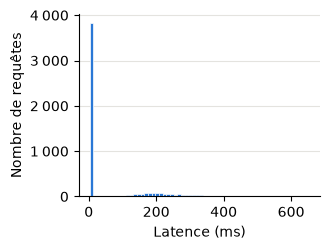

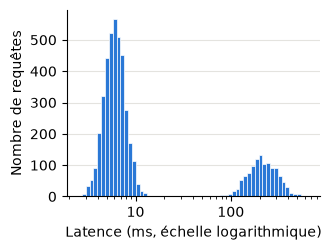

In [498]:
# [IA] Code généré par Claude : histogrammes des latences en échelle linéaire et logarithmique (jeu 4, Q2)
# Deux figures séparées (une par échelle), placées côte à côte dans le rapport.
# Échelle log : axe des x logarithmique et classes de largeur égale en log
# (sinon les classes paraissent de plus en plus larges vers la droite).
latence = df_j4["latence_ms"]
n_classes = 60

def mise_en_forme_hist(ax):
    ax.set_ylabel("Nombre de requêtes")
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for cote in ("top", "right"):
        ax.spines[cote].set_visible(False)
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}".replace(",", " "))

# Échelle linéaire
fig, ax = plt.subplots(figsize=(3.4, 2.6))
ax.hist(latence, bins=n_classes, color="#2a78d6", edgecolor="white", linewidth=0.5)
ax.set_xlabel("Latence (ms)")
mise_en_forme_hist(ax)
fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "jeu4_hist_lin.pdf")
plt.show()

# Échelle logarithmique
classes_log = np.logspace(np.log10(latence.min()), np.log10(latence.max()), n_classes + 1)
fig, ax = plt.subplots(figsize=(3.4, 2.6))
ax.hist(latence, bins=classes_log, color="#2a78d6", edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
ax.set_xlabel("Latence (ms, échelle logarithmique)")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}".replace(".", ","))
mise_en_forme_hist(ax)
fig.tight_layout()
fig.savefig(DOSSIER_FIGURES / "jeu4_hist_log.pdf")
plt.show()

### q3 Cherchez dans les autres colonnes une explication à la forme de la distribution observée. Justifiez chiffres à l’appui. Indiquez également les pistes que vous avez examinées puis écartées, avec les mesures qui vous ont conduit à les écarter.

REgardons si l'heure de la journée a une corrélation avec la latence.

In [499]:
# [IA] Code généré par Claude : latence par heure de la journée (effectif, moyenne, médiane, écart-type)
heure = pd.to_datetime(df_j4["horodatage"]).dt.hour
latence_par_heure = (
    df_j4.groupby(heure)["latence_ms"]
    .agg(["count", "mean", "median", "std"])
    .rename(columns={"count": "Effectif", "mean": "Moyenne (ms)",
                     "median": "Médiane (ms)", "std": "Écart-type (ms)"})
    .rename_axis("Heure")
    .round(1)
)
latence_par_heure

,Effectif,Moyenne (ms),Médiane (ms),Écart-type (ms)
Heure,,,,
8,665,57.5,6.5,98.7
9,579,59.4,6.6,97.6
10,634,55.7,6.6,98.8
11,565,59.7,6.7,104.0
12,672,58.6,6.5,109.0
13,617,54.9,6.6,102.0
14,606,65.8,6.8,110.4
15,662,55.1,6.7,100.0


In [500]:
# [IA] Code généré par Claude : latence selon le nombre de requêtes dans la même minute
# Chaque requête reçoit le nombre de requêtes de sa minute (horodatage tronqué à la minute).
minute = pd.to_datetime(df_j4["horodatage"]).dt.floor("min")
requetes_par_minute = minute.map(minute.value_counts())

latence_par_charge = (
    df_j4.groupby(requetes_par_minute)["latence_ms"]
    .agg(["count", "mean", "median", "std"])
    .rename(columns={"count": "Requêtes", "mean": "Moyenne (ms)",
                     "median": "Médiane (ms)", "std": "Écart-type (ms)"})
)
# Nombre de minutes ayant ce nombre de requêtes (= Requêtes / nombre par minute).
latence_par_charge.insert(0, "Minutes", latence_par_charge["Requêtes"] // latence_par_charge.index)
latence_par_charge = latence_par_charge.rename_axis("Requêtes par minute").round(1)
latence_par_charge

,Minutes,Requêtes,Moyenne (ms),Médiane (ms),Écart-type (ms)
Requêtes par minute,,,,,
2,1,2,232.6,232.6,64.4
3,5,15,42.9,6.6,81.4
4,7,28,57.9,6.4,96.1
5,13,65,49.8,6.4,98.0
6,42,252,70.6,6.8,115.6
7,35,245,52.3,6.6,95.7
8,39,312,58.8,6.6,105.7
9,50,450,58.8,6.8,96.6
10,61,610,59.0,6.5,105.6


In [501]:
# [IA] Code généré par Claude : latence selon le nombre de requêtes déjà en cours au début de chaque requête
# Hypothèse : horodatage = début de la requête ; fin = début + latence.
# On compte les requêtes en cours AU DÉBUT de chaque requête (et non pendant toute sa durée :
# une requête longue chevaucherait mécaniquement plus de requêtes, ce qui fausserait le lien).
debut = pd.to_datetime(df_j4["horodatage"])
fin = debut + pd.to_timedelta(df_j4["latence_ms"], unit="ms")

debuts_tries = np.sort(debut.values)
fins_triees = np.sort(fin.values)
deja_commencees = np.searchsorted(debuts_tries, debut.values, side="right")  # elle-même incluse
deja_terminees = np.searchsorted(fins_triees, debut.values, side="right")
requetes_en_cours = pd.Series(deja_commencees - deja_terminees - 1, index=df_j4.index)

latence_par_concurrence = (
    df_j4.groupby(requetes_en_cours)["latence_ms"]
    .agg(["count", "mean", "median", "std"])
    .rename(columns={"count": "Requêtes", "mean": "Moyenne (ms)",
                     "median": "Médiane (ms)", "std": "Écart-type (ms)"})
    .rename_axis("Requêtes déjà en cours")
    .round(1)
)
latence_par_concurrence

,Requêtes,Moyenne (ms),Médiane (ms),Écart-type (ms)
Requêtes déjà en cours,,,,
0,4946,58.2,6.6,102.6
1,54,60.7,6.8,105.7


In [502]:
# [IA] Code généré par Claude : latence selon le nombre de requêtes commencées dans la minute précédente
# Fenêtre glissante : requêtes commencées dans les 60 s avant le début de chaque requête (elle-même exclue).
# Les requêtes encore en cours y sont incluses (toutes durent moins d'une seconde).
debuts = pd.to_datetime(df_j4["horodatage"]).values
debuts_tries = np.sort(debuts)
requetes_minute_precedente = pd.Series(
    np.searchsorted(debuts_tries, debuts, side="left")
    - np.searchsorted(debuts_tries, debuts - np.timedelta64(60, "s"), side="left"),
    index=df_j4.index,
)

latence_par_minute_precedente = (
    df_j4.groupby(requetes_minute_precedente)["latence_ms"]
    .agg(["count", "mean", "median", "std"])
    .rename(columns={"count": "Requêtes", "mean": "Moyenne (ms)",
                     "median": "Médiane (ms)", "std": "Écart-type (ms)"})
    .rename_axis("Requêtes dans la minute précédente")
    .round(1)
)
latence_par_minute_precedente

,Requêtes,Moyenne (ms),Médiane (ms),Écart-type (ms)
Requêtes dans la minute précédente,,,,
0,1,4.8,4.8,NaN
1,2,9.4,9.4,4.2
2,8,23.1,7.5,46.0
3,38,54.8,6.6,101.4
4,94,29.8,6.1,62.8
5,165,61.4,6.6,103.0
6,274,57.8,6.6,103.3
7,394,56.0,6.8,98.0
8,472,62.6,6.8,101.0


PLusieurs facteurs temporels ont été explorés, sans résultat prometteurs. recardons les autres attributs.

In [503]:
# [IA] Code généré par Claude : latence par endpoint et par version du service (effectif, moyenne, médiane, écart-type), export du tableau par version
noms_stats = {"count": "Requêtes", "mean": "Moyenne (ms)",
              "median": "Médiane (ms)", "std": "Écart-type (ms)"}

latence_par_endpoint = (
    df_j4.groupby("endpoint")["latence_ms"]
    .agg(["count", "mean", "median", "std"]).rename(columns=noms_stats).round(1)
)
latence_par_version = (
    df_j4.groupby("version_service")["latence_ms"]
    .agg(["count", "mean", "median", "std"]).rename(columns=noms_stats).round(1)
)

display(latence_par_endpoint)
display(latence_par_version)

# Tableau par version pour le rapport (format_nombre défini plus haut) ;
# les numéros de version gardent leurs points.
latence_par_version_tex = pd.DataFrame({
    "Version du service": latence_par_version.index.astype(str),
    "Requêtes": latence_par_version["Requêtes"].map(lambda x: format_nombre(x, 0)).values,
    "Moyenne (ms)": latence_par_version["Moyenne (ms)"].map(format_nombre).values,
    "Médiane (ms)": latence_par_version["Médiane (ms)"].map(format_nombre).values,
    "Écart-type (ms)": latence_par_version["Écart-type (ms)"].map(format_nombre).values,
})
ecrire_tableau("jeu4-Q3-version", latence_par_version_tex, index=False, column_format="lrrrr")

,Requêtes,Moyenne (ms),Médiane (ms),Écart-type (ms)
endpoint,,,,
/api/panier,1745,59.4,6.6,103.3
/api/profil,1607,59.5,6.6,105.1
/api/recherche,1648,55.9,6.6,99.5


,Requêtes,Moyenne (ms),Médiane (ms),Écart-type (ms)
version_service,,,,
2.3.1,4028,31.6,6.3,76.5
2.4.0,972,168.5,183.6,121.8


tableau écrit dans resultats/jeu4-Q3-version.tex
